# 05 · Séries temporais da cafeicultura paulista

**Coffee Big Data Intelligence**

> **Aviso central:** séries anuais curtas (CONAB: 25 safras de arábica em SP; PAM: 52 anos). Estatística de séries com *n* assim é **frágil**: intervalos largos e conclusões provisórias são o resultado honesto.

## Objetivos
1. Caracterizar **tendência** e **bienalidade** (alternância de safras altas e baixas) na produção de SP.
2. Comparar **previsores simples** em validação de **origem móvel** (*rolling origin*): sem olhar o futuro.
3. Associar **incerteza** às previsões (intervalos empíricos) e medir se a cobertura declarada se confirma.
4. Relacionar, **de forma apenas descritiva**, preço real e produção.

## Séries usadas
| Série | Fonte | Granularidade | Observação |
|---|---|---|---|
| Produção de **arábica** SP, 2001–2025 | CONAB (mil sacas de 60 kg) | UF × safra | safra 2026 é **estimativa**, tratada à parte |
| Café **total** SP, 1974–2025 | IBGE/PAM (t) | UF × ano | espécies não separadas antes de 2012 |

Arábica e conilon **não são misturados** na série principal (CONAB separa por espécie; em SP o conilon é desprezível).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coffeebdi import config, silver, modeling as M, quality
from coffeebdi.lake import Lake
from coffeebdi.nbutils import duck, mpl_style

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.2f}".format)
mpl_style()
lake = Lake()
con = duck(lake)
def q(sql):
    """Executa SQL (DuckDB) sobre as tabelas silver/gold e devolve DataFrame."""
    return con.execute(sql).df()
FIG = config.OUTPUTS / "figures"
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
conab = q('''SELECT safra AS ano, valor AS mil_sacas, estimativa FROM conab_uf
             WHERE uf='SP' AND especie='arabica' AND indicador='producao_mil_sacas' ORDER BY safra''')
pam = q('''SELECT ano, quantidade_t/1e3 AS kt FROM pam_uf WHERE uf='SP' AND especie='total' ORDER BY ano''')
print("CONAB: safras", conab.ano.min(), "–", conab.ano.max(), "| linhas marcadas como estimativa:", conab[conab.estimativa].ano.tolist())
hist = conab[~conab.estimativa].reset_index(drop=True)      # série de fechadas (2001–2025)
est2026 = conab[conab.estimativa]
print(f"Série fechada: {len(hist)} safras | PAM: {len(pam)} anos")
hist.tail(6)

CONAB: safras 2001 – 2026 | linhas marcadas como estimativa: [2026]
Série fechada: 25 safras | PAM: 52 anos


,ano,mil_sacas,estimativa
19,2020,"6,180.70",False
20,2021,"4,007.20",False
21,2022,"4,387.00",False
22,2023,"5,030.70",False
23,2024,"5,444.60",False
24,2025,"4,739.90",False


## 1. Tendência e bienalidade

**Medidas** (série em log, *y<sub>t</sub> = ln P<sub>t</sub>*):

- **Variação log anual:** *d<sub>t</sub> = y<sub>t</sub> − y<sub>t−1</sub>* ≈ variação percentual.
- **Alternância:** fração de anos em que o *sinal* de *d<sub>t</sub>* é oposto ao de *d<sub>t−1</sub>* (50% seria aleatório; 100%, alternância perfeita).
- **Autocorrelação (ACF) de lag *k*** do resíduo da tendência: *ρ<sub>k</sub> = Cov(r<sub>t</sub>, r<sub>t−k</sub>)/Var(r)*. Bienalidade ⇒ ρ₁ negativa e ρ₂ positiva.

Com *n* ≈ 25, a banda de ±1,96/√*n* ≈ ±0,39 é a referência de "indistinguível de ruído branco".

In [3]:
def diag(y, ano, nome):
    y = np.log(np.asarray(y, float))
    d = np.diff(y)
    flips = np.mean(np.sign(d[1:]) != np.sign(d[:-1]))
    r = y - np.polyval(np.polyfit(ano, y, 1), ano)
    acf = [pd.Series(r).autocorr(k) for k in (1, 2, 3)]
    return {"série": nome, "n": len(y), "% alternância de sinal": 100 * flips,
            "ACF lag1": acf[0], "ACF lag2": acf[1], "ACF lag3": acf[2], "banda ±1,96/√n": 1.96 / np.sqrt(len(y))}

tab = pd.DataFrame([
    diag(hist.mil_sacas, hist.ano, "CONAB arábica SP 2001–2025"),
    diag(pam[pam.ano >= 2001].kt, pam[pam.ano >= 2001].ano, "PAM total SP 2001–2025"),
    diag(pam.kt, pam.ano, "PAM total SP 1974–2025"),
    diag(pam[pam.ano >= 2012].kt, pam[pam.ano >= 2012].ano, "PAM total SP 2012–2025")]).set_index("série")
tab.round(2)

,n,% alternância de sinal,ACF lag1,ACF lag2,ACF lag3,"banda ±1,96/√n"
série,,,,,,
CONAB arábica SP 2001–2025,25,91.30,-0.64,0.70,-0.62,0.39
PAM total SP 2001–2025,25,86.96,-0.24,0.13,-0.22,0.39
PAM total SP 1974–2025,52,76.00,0.22,0.25,0.32,0.27
PAM total SP 2012–2025,14,83.33,-0.68,0.53,-0.39,0.52


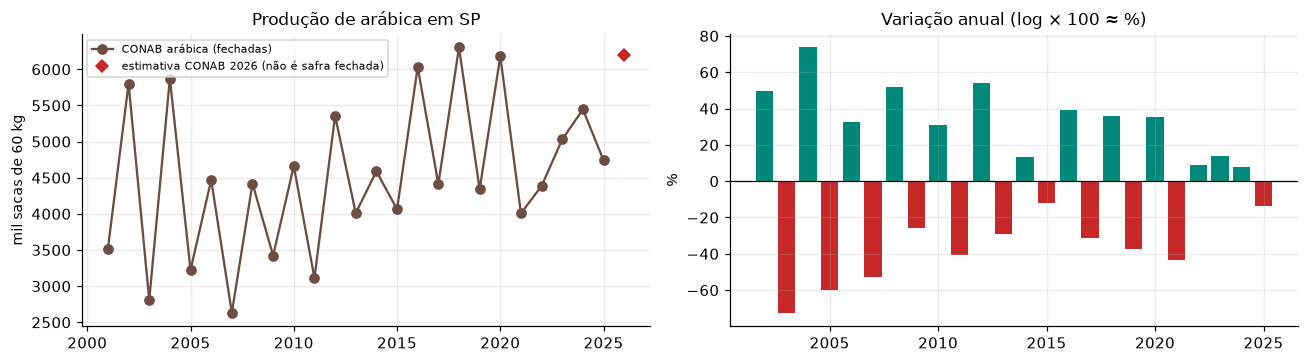

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(hist.ano, hist.mil_sacas, "o-", color="#6d4c41", label="CONAB arábica (fechadas)")
ax[0].plot(est2026.ano, est2026.mil_sacas, "D", color="#c62828", label="estimativa CONAB 2026 (não é safra fechada)")
ax[0].set(title="Produção de arábica em SP", ylabel="mil sacas de 60 kg"); ax[0].legend(fontsize=7)
d = np.diff(np.log(hist.mil_sacas.values))
ax[1].bar(hist.ano[1:], 100 * d, color=np.where(d > 0, "#00897b", "#c62828"))
ax[1].axhline(0, color="k", lw=.8); ax[1].set(title="Variação anual (log × 100 ≈ %)", ylabel="%")
plt.tight_layout(); plt.savefig(FIG / "05_serie_conab.png"); plt.show()

**Como ler:** a tabela e o gráfico de barras mostram se o sinal da variação alterna (verde/vermelho alternando). Compare cada ACF com a banda: valores dentro dela **não** se distinguem de ruído. A série PAM 1974–2025 mostra alternância menos clara (quebras estruturais: queda de área e mudanças de manejo ao longo de décadas contaminam a ACF linear). Para a agronomia: o cafeeiro arábica tem ciclo **bienal** porque uma carga alta esgota reservas e reduz a formação de ramos produtivos para o ano seguinte; poda e manejo (como o *esqueletamento*) podem alterar esse ritmo — **o dado agregado não permite atribuir a causa**.

## 2. Previsão por origem móvel

Para cada ano-alvo *T* de 2010 a 2025, **só** a história até *T*−1 é usada. Previsores:

| Modelo | Fórmula | Ideia |
|---|---|---|
| `naive` | ŷ<sub>T</sub> = y<sub>T−1</sub> | "repete o ano passado" |
| `naive_lag2` | ŷ<sub>T</sub> = y<sub>T−2</sub> | **bienal ingênuo**: repete a safra de dois anos atrás |
| `media_2` | média(y<sub>T−1</sub>, y<sub>T−2</sub>) | suaviza a alternância |
| `media_5` | média dos 5 últimos | nível de médio prazo |
| `ar2` | y<sub>T</sub> = a + b₁y<sub>T−1</sub> + b₂y<sub>T−2</sub> (OLS na história) | captura persistência e alternância |
| `ets_amort` | suavização exponencial com tendência amortecida | nível + tendência que se esgota |

Intervalos: quantis **empíricos dos erros de origens anteriores** (erro percentual, para respeitar a escala), nível nominal 80%. Só há intervalo a partir do 4º ano-alvo.

In [5]:
def fc_naive(h):      return h[-1]
def fc_naive2(h):     return h[-2]
def fc_media2(h):     return h[-2:].mean()
def fc_media5(h):     return h[-5:].mean()
def fc_ar2(h):
    X = np.column_stack([np.ones(len(h) - 2), h[1:-1], h[:-2]]); y = h[2:]
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    return b[0] + b[1] * h[-1] + b[2] * h[-2]
def fc_ets(h):
    m = ExponentialSmoothing(h, trend="add", damped_trend=True, initialization_method="estimated").fit()
    return float(m.forecast(1)[0])
MODELS = {"naive": fc_naive, "naive_lag2": fc_naive2, "media_2": fc_media2, "media_5": fc_media5, "ar2": fc_ar2, "ets_amort": fc_ets}

def rolling(series, anos, first, fcs=MODELS):
    rows = []
    for T in range(first, anos.max() + 1):
        h = series[anos < T]
        for nm, f in fcs.items():
            rows.append({"ano": T, "modelo": nm, "real": series[anos == T][0], "previsto": float(f(h))})
    return pd.DataFrame(rows)

y = hist.mil_sacas.values.astype(float); anos = hist.ano.values
bt = rolling(y, anos, 2010)
bt["erro"] = bt.real - bt.previsto
score = bt.groupby("modelo").apply(lambda g: pd.Series({
    "MAE (mil sacas)": M.mae(g.real, g.previsto), "RMSE": M.rmse(g.real, g.previsto),
    "sMAPE (%)": M.smape(g.real, g.previsto), "WAPE (%)": M.wape(g.real, g.previsto),
    "viés médio": g.erro.mean()})).sort_values("MAE (mil sacas)")
print(f"{bt.ano.nunique()} anos-alvo ({bt.ano.min()}–{bt.ano.max()}) por modelo")
score.round(1)

16 anos-alvo (2010–2025) por modelo


,MAE (mil sacas),RMSE,sMAPE (%),WAPE (%),viés médio
modelo,,,,,
naive_lag2,607.60,787.00,12.90,12.70,146.30
ar2,654.20,829.10,14.10,13.70,367.20
ets_amort,805.40,"1,017.20",17.10,16.80,291.00
media_2,813.80,918.40,17.10,17.00,114.30
media_5,831.80,"1,003.50",17.60,17.40,231.20
naive,"1,317.60","1,471.90",27.60,27.50,82.30


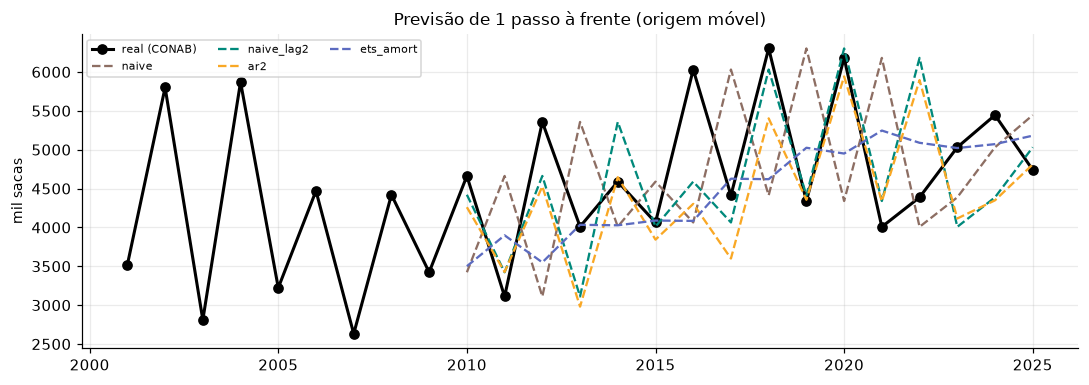

In [6]:
piv = bt.pivot(index="ano", columns="modelo", values="previsto")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hist.ano, hist.mil_sacas, "ko-", lw=2, label="real (CONAB)")
for nm, col in zip(["naive", "naive_lag2", "ar2", "ets_amort"], ["#8d6e63", "#00897b", "#f9a825", "#5c6bc0"]):
    ax.plot(piv.index, piv[nm], "--", color=col, label=nm)
ax.set(ylabel="mil sacas", title="Previsão de 1 passo à frente (origem móvel)"); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.savefig(FIG / "05_rolling_origin.png"); plt.show()

**Como ler:** a tabela ordena por MAE. **Atenção a dois pontos:** (i) com ~16 anos-alvo, a diferença entre modelos próximos **não é estatisticamente significativa** — uma safra atípica muda o ranking; (ii) `naive_lag2` só vence se a alternância for regular. Se um modelo sofisticado (`ar2`, `ets_amort`) não bater o baseline, **o baseline é a resposta correta**. O viés médio mostra se o modelo erra sistematicamente para cima ou para baixo.

### 2.1 Os erros são distinguíveis? Teste pareado simples

Para não superinterpretar o ranking, comparamos o **erro absoluto** de cada modelo com o do `naive` por **bootstrap dos anos-alvo** (reamostragem dos pares). Se o intervalo de confiança da diferença incluir 0, não há evidência de melhora.

In [7]:
rng = np.random.default_rng(0)
ae = bt.assign(ae=bt.erro.abs()).pivot(index="ano", columns="modelo", values="ae")
rows = []
for m in ae.columns.drop("naive"):
    diff = (ae["naive"] - ae[m]).values       # >0 ⇒ m melhor que naive
    bs = [rng.choice(diff, len(diff), replace=True).mean() for _ in range(2000)]
    rows.append({"modelo": m, "ganho médio em MAE vs naive (mil sacas)": diff.mean(),
                 "IC95_inf": np.percentile(bs, 2.5), "IC95_sup": np.percentile(bs, 97.5)})
cmp_ = pd.DataFrame(rows).set_index("modelo"); cmp_["IC inclui 0?"] = (cmp_.IC95_inf < 0) & (cmp_.IC95_sup > 0)
cmp_.round(1)

,ganho médio em MAE vs naive (mil sacas),IC95_inf,IC95_sup,IC inclui 0?
modelo,,,,
ar2,663.40,250.50,"1,074.90",False
ets_amort,512.20,263.80,771.20,False
media_2,503.80,273.30,717.30,False
media_5,485.80,261.40,711.20,False
naive_lag2,710.00,225.70,"1,140.30",False


**Como ler:** ganho positivo = o modelo erra menos que o `naive`. Se `IC inclui 0? = True`, a vantagem aparente pode ser sorte amostral. Esse tipo de verificação é a defesa contra "escolher o vencedor do backtest" (*winner's curse*).

## 3. Intervalos de previsão e cobertura

Erro **relativo** *e<sub>t</sub> = (y<sub>t</sub> − ŷ<sub>t</sub>)/ŷ<sub>t</sub>*, calculado nas origens **anteriores**. Para o ano *T*, o intervalo de 80% é

  ŷ<sub>T</sub> · (1 + q<sub>10</sub>(e)) a ŷ<sub>T</sub> · (1 + q<sub>90</sub>(e)),

com quantis dos erros relativos dos anos < *T*. **Cobertura** = fração dos anos em que o real caiu dentro do intervalo; esperada ≈ 80%.

In [8]:
def intervals(bt, modelo, alpha=0.2, min_cal=4):
    g = bt[bt.modelo == modelo].sort_values("ano").reset_index(drop=True)
    g["erro_rel"] = (g.real - g.previsto) / g.previsto
    lo, hi = [], []
    for i in range(len(g)):
        e = g.erro_rel.iloc[:i]
        if len(e) < min_cal: lo.append(np.nan); hi.append(np.nan); continue
        lo.append(g.previsto[i] * (1 + np.quantile(e, alpha / 2))); hi.append(g.previsto[i] * (1 + np.quantile(e, 1 - alpha / 2)))
    g["lo"], g["hi"] = lo, hi
    g["dentro"] = np.where(g.lo.notna(), (g.real >= g.lo) & (g.real <= g.hi), np.nan)
    return g

best = score.index[0]
rows = []
for m in ["naive", "naive_lag2", "media_2", "ar2", "ets_amort"]:
    g = intervals(bt, m); v = g.dropna(subset=["lo"])
    rows.append({"modelo": m, "anos com intervalo": len(v), "cobertura (nominal 80%)": 100 * v.dentro.mean(),
                 "largura média (mil sacas)": (v.hi - v.lo).mean()})
cov = pd.DataFrame(rows).set_index("modelo"); print("Melhor por MAE:", best)
cov.round(1)

Melhor por MAE: naive_lag2


,anos com intervalo,cobertura (nominal 80%),largura média (mil sacas)
modelo,,,
naive,12,83.30,"4,055.70"
naive_lag2,12,75.00,"1,841.10"
media_2,12,66.70,"2,592.00"
ar2,12,75.00,"1,746.90"
ets_amort,12,75.00,"2,850.70"


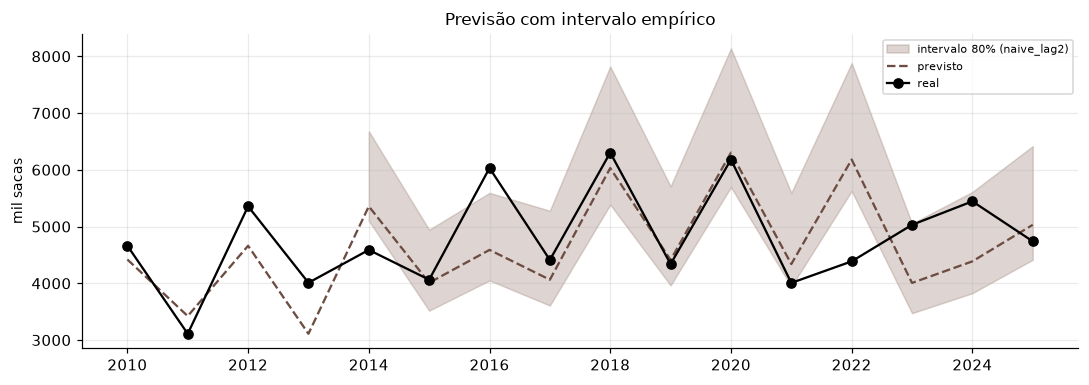

In [9]:
g = intervals(bt, best)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(g.ano, g.lo, g.hi, color="#a1887f", alpha=.35, label=f"intervalo 80% ({best})")
ax.plot(g.ano, g.previsto, "--", color="#6d4c41", label="previsto"); ax.plot(g.ano, g.real, "ko-", label="real")
ax.set(ylabel="mil sacas", title="Previsão com intervalo empírico"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "05_intervalos.png"); plt.show()

**Como ler:** com poucos anos de calibração (a partir de 4) os quantis 10%/90% são estimados com **pouquíssimos pontos**; a cobertura observada pode ficar bem abaixo ou acima de 80% sem que isso contradiga o método. **O intervalo é condicional ao regime passado**: uma geada severa ou mudança de manejo fora da amostra não está nele.

## 4. Preço e produção: relação **descritiva**

Pergunta: variações anuais da produção paulista acompanham o preço real (BRL/saca, deflacionado pelo IPCA) do mesmo ano ou do ano anterior? Usamos correlação de postos entre **variações logarítmicas**, para retirar tendências. **Correlação ≠ causalidade**: preço e produção respondem a clima comum (geada no Brasil eleva preço **e** reduz produção — sinal negativo sem que o preço "cause" a queda) e a decisões de manejo defasadas.

In [10]:
pr = q("select ano, brl_saca_real_2025 as preco_real from precos_anuais").set_index("ano").preco_real
df = hist.set_index("ano")[["mil_sacas"]].join(pr, how="inner")
df["d_prod"] = np.log(df.mil_sacas).diff(); df["d_preco"] = np.log(df.preco_real).diff()
df["d_preco_lag1"] = df.d_preco.shift(1)
rows = []
for c in ["d_preco", "d_preco_lag1"]:
    s = df[["d_prod", c]].dropna(); rho, p = stats.spearmanr(s.d_prod, s[c])
    bs = [stats.spearmanr(*s.sample(len(s), replace=True, random_state=i).T.values)[0] for i in range(500)]
    rows.append({"relação": f"Δln produção × {c}", "n": len(s), "ρ de Spearman": rho, "p": p, "IC95_inf": np.nanpercentile(bs, 2.5), "IC95_sup": np.nanpercentile(bs, 97.5)})
pd.DataFrame(rows).set_index("relação").round(2)

,n,ρ de Spearman,p,IC95_inf,IC95_sup
relação,,,,,
Δln produção × d_preco,24,-0.06,0.79,-0.40,0.33
Δln produção × d_preco_lag1,23,-0.17,0.45,-0.52,0.26


**Como ler:** se o IC cruza 0, não há evidência de associação com este *n*. Mesmo quando houver, a leitura é **descritiva**: o preço do ano *t* é conhecido quando a safra *t* já está formada (a colheita é abr–set), e o preço do ano *t*−1 pode influenciar investimento, não a carga já definida pela florada. Para política ou investimento, seriam necessários modelos estruturais e dados de custo, **fora do escopo** deste projeto.

## 5. A estimativa CONAB de 2026 frente aos previsores

A safra 2026 aparece na base como **estimativa** (não é dado fechado). Mostramos as previsões que os modelos teriam feito **com a história até 2025** apenas para comparação de ordem de grandeza. **Não é validação**: não há realizado ainda.

In [11]:
rows = [{"fonte": nm, "mil sacas": float(f(y))} for nm, f in MODELS.items()]
rows.append({"fonte": "CONAB (estimativa, a confirmar)", "mil sacas": float(est2026.mil_sacas.iloc[0])})
cmp26 = pd.DataFrame(rows).set_index("fonte"); cmp26["vs. safra 2025 (%)"] = 100 * (cmp26["mil sacas"] / y[-1] - 1)
print(f"Safra 2025 (fechada): {y[-1]:,.0f} mil sacas | média 2021–2025: {y[-5:].mean():,.0f} mil sacas")
cmp26.round(1)

Safra 2025 (fechada): 4,740 mil sacas | média 2021–2025: 4,722 mil sacas


,mil sacas,vs. safra 2025 (%)
fonte,,
naive,"4,739.90",0.00
naive_lag2,"5,444.60",14.90
media_2,"5,092.20",7.40
media_5,"4,721.90",-0.40
ar2,"5,139.70",8.40
ets_amort,"5,163.80",8.90
"CONAB (estimativa, a confirmar)","6,192.00",30.60


**Como ler:** todos os previsores estatísticos ficam entre −0,4% e +14,9% sobre 2025, enquanto a estimativa da CONAB está **bem acima** (veja a coluna de variação). Duas leituras possíveis, que este notebook **não consegue distinguir**: (a) a CONAB incorpora informação de campo (floração, área em produção, clima da safra) que os previsores não têm; (b) uma estimativa antecipada pode ser revista depois — **a magnitude histórica dessas revisões não foi avaliada aqui**. Previsores que "repetem" ou "alternam" **não conhecem** a safra 2026. Compare novamente quando a safra for fechada.

## 6. Resumo interpretativo

| Pergunta | Evidência neste notebook | Limite |
|---|---|---|
| Há bienalidade na produção de SP? | tabela da seção 1: alternância de sinal e ACF lag1/lag2 | *n* pequeno; ACF perto da banda de ruído deve ser lido com cautela |
| Modelos sofisticados batem baselines? | seção 2 e IC pareado | 16 anos-alvo; poder estatístico baixo |
| Os intervalos têm cobertura correta? | seção 3 | calibração com 4–15 pontos |
| Preço explica produção? | seção 4 (descritivo) | confusão por clima; *n* ≈ 24 |

## Exercícios
1. Troque `first` em `rolling(...)` para 2005 e 2015: o ranking dos modelos muda? O que isso diz sobre estabilidade?
2. Adicione um modelo `media_ponderada` (pesos 0,6 e 0,4 nos dois últimos anos) e use o IC pareado para avaliar se ele melhora o `naive`.
3. Repita o diagnóstico de bienalidade com a série PAM de **2012 em diante** e compare com a CONAB. Por que podem divergir (conceito, metodologia, espécie)?
4. Calcule o intervalo com nível 50% e 90%. A cobertura acompanha o nível nominal?
5. Por que o intervalo empírico baseado em erros **relativos** é preferível ao baseado em erros absolutos quando a série cresce ou cai muito?